# Entrega 1 — Entendimiento del negocio y de los datos
**Proyecto:** Predicción de cancelaciones de reservas hoteleras
**Curso:** Aprendizaje Máquina I — Maestría en Ciencia de Datos, Universidad Panamericana

Este cuaderno cubre las fases 1 y 2 de CRISP-DM:

1. **Entendimiento del negocio:** cuantificación de los KPIs que el modelo debe impactar.
2. **Entendimiento de los datos:** calidad (nulos, duplicados, inconsistencias, *outliers*),
   distribución de la variable objetivo, auditoría de fuga de información (*data leakage*),
   patrones clave y correlaciones.

**Regla de oro de esta entrega:** aquí *no* se transforma ni se imputa nada. Todo el
análisis es descriptivo sobre los datos crudos; cualquier ajuste (imputadores, escaladores,
codificadores) se hará en la Entrega 2 **dentro** de un `Pipeline` ajustado solo con el
conjunto de entrenamiento, para evitar fuga de información.

Todas las figuras y tablas del reporte LaTeX se generan desde este cuaderno
(`../report/figuras/` y `../report/tablas/`).

## 0. Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, spearmanr

SEED = 42
np.random.seed(SEED)

RAIZ = Path("..").resolve()
DATOS = RAIZ / "data" / "raw" / "hotels.csv"
FIG = RAIZ / "report" / "figuras"
TAB = RAIZ / "report" / "tablas"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

# Paleta (validada para daltonismo en pares adyacentes): azul = no cancelada, naranja = cancelada
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#898781"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e1e0d9"

plt.rcParams.update({
    "font.family": "Inter", "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.labelsize": 9, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA2,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 300,
    "savefig.bbox": "tight", "pdf.fonttype": 42,
})


def guardar(fig, nombre):
    """Exporta la figura en PDF (para LaTeX) y PNG (para la presentación)."""
    fig.savefig(FIG / f"{nombre}.pdf")
    fig.savefig(FIG / f"{nombre}.png")


def pct(x, dec=1):
    return f"{100 * x:.{dec}f}\\%"

## 1. Carga y verificación de la fuente

**Fuente:** *Hotel Booking Demand* (Antonio, de Almeida y Nunes, 2019, *Data in Brief*, 22, 41–49,
DOI 10.1016/j.dib.2018.11.126). Los datos se extrajeron por consultas T-SQL del sistema de gestión
hotelera (PMS) de dos hoteles en Portugal: H1 (resort, Algarve) y H2 (hotel urbano, Lisboa),
con llegadas entre el 1 de julio de 2015 y el 31 de agosto de 2017. Se usa la versión combinada
en CSV publicada por el proyecto TidyTuesday (2020-02-11), que une ambos archivos y añade la
columna `hotel`.

**Decisión semántica clave:** según el artículo fuente, el valor `NULL` en `agent` y `company`
significa *no aplica* (la reserva no vino de una agencia / no la paga una empresa), **no**
"dato faltante". Por eso se lee `NULL` como `NaN` solo para contarlo, pero se interpretará como
una categoría propia en la Entrega 2.

In [2]:
df = pd.read_csv(DATOS, na_values=["NULL", "NA"], keep_default_na=False, low_memory=False)
print(df.shape)
assert df.shape == (119390, 32), "El archivo no coincide con la versión esperada"
print(df.groupby("hotel").size())  # Debe coincidir con el artículo: 40,060 (H1) y 79,330 (H2)
df.head()

(119390, 32)
hotel
City Hotel      79330
Resort Hotel    40060
dtype: int64


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
# Variable auxiliar solo para análisis (no se usará como feature en esta forma)
df["noches"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["huespedes"] = df["adults"] + df["children"].fillna(0) + df["babies"]
df["fecha_llegada"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" + df["arrival_date_month"] + "-"
    + df["arrival_date_day_of_month"].astype(str), format="%Y-%B-%d")
Y = "is_canceled"

## 2. Entendimiento del negocio: KPIs de línea base

El modelo debe impactar tres KPIs:

- **Tasa de cancelación** (reservas canceladas / reservas totales).
- **Ingreso en riesgo**: ingreso de habitación comprometido por reservas que luego se cancelan,
  aproximado como `adr × noches`.
- **Habitaciones-noche perdidas**: capacidad que queda vacía si la cancelación no se anticipa.

Se calculan con el registro histórico completo como línea base del negocio (no como métrica del modelo).

In [4]:
ingreso = df["adr"].clip(lower=0) * df["noches"]  # el único ADR negativo se trunca a 0 solo para el KPI
kpi = (df.assign(ingreso=ingreso)
         .groupby("hotel")
         .apply(lambda g: pd.Series({
             "Reservas": len(g),
             "Tasa de cancelación": g[Y].mean(),
             "Ingreso total reservado": g["ingreso"].sum(),
             "Ingreso en riesgo (cancelado)": g.loc[g[Y] == 1, "ingreso"].sum(),
             "Habitaciones-noche canceladas": g.loc[g[Y] == 1, "noches"].sum(),
         }), include_groups=False))
kpi.loc["Total"] = [len(df), df[Y].mean(), ingreso.sum(), ingreso[df[Y] == 1].sum(),
                    df.loc[df[Y] == 1, "noches"].sum()]
kpi["% del ingreso en riesgo"] = kpi["Ingreso en riesgo (cancelado)"] / kpi["Ingreso total reservado"]
kpi

,Reservas,Tasa de cancelación,Ingreso total reservado,Ingreso en riesgo (cancelado),Habitaciones-noche canceladas,% del ingreso en riesgo
hotel,,,,,,
City Hotel,79330.0,0.417270,25279469.96,10885059.78,101103.0,0.430589
Resort Hotel,40060.0,0.277634,17444091.37,5842177.34,53114.0,0.334909
Total,119390.0,0.370416,42723561.33,16727237.12,154217.0,0.391523


In [5]:
with open(TAB / "kpis.tex", "w") as f:
    for h, r in kpi.iterrows():
        nombre = {"City Hotel": "Hotel urbano (H2)", "Resort Hotel": "Hotel resort (H1)"}.get(h, "\\textbf{Total}")
        f.write(f"{nombre} & {int(r['Reservas']):,} & {pct(r['Tasa de cancelación'])} & "
                f"{r['Ingreso en riesgo (cancelado)'] / 1e6:,.2f} & {pct(r['% del ingreso en riesgo'])} & "
                f"{int(r['Habitaciones-noche canceladas']):,} \\\\\n")

## 3. Calidad de datos
### 3.1 Valores nulos y su significado

In [6]:
nulos = df.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False).to_frame("n")
nulos["%"] = nulos["n"] / len(df)
nulos["Tasa de cancelación si nulo"] = [df.loc[df[c].isna(), Y].mean() for c in nulos.index]
nulos["Tasa de cancelación si no nulo"] = [df.loc[df[c].notna(), Y].mean() for c in nulos.index]
nulos

,n,%,Tasa de cancelación si nulo,Tasa de cancelación si no nulo
company,112593,0.943069,0.382200,0.175224
agent,16340,0.136862,0.246634,0.390044
country,488,0.004087,0.137295,0.371373
children,4,0.000034,1.000000,0.370395


**Lectura:** solo `children` (4 filas) y `country` (488 filas) son faltantes "verdaderos".
`agent` y `company` son *no aplica*. Además, la nulidad es **informativa**: las reservas sin
país registrado se cancelan mucho menos (13.7 % vs 37.1 %), lo cual es coherente con que el
país se capture o corrija al llegar el huésped (ver auditoría de fuga, §5). Imputar `country`
con la moda (PRT) destruiría esta señal y además la mezclaría con la categoría más sospechosa.

### 3.2 Duplicados

In [7]:
analisis = ["noches", "huespedes", "fecha_llegada"]
dup = df.drop(columns=analisis).duplicated(keep=False)
n_dup_extra = df.drop(columns=analisis).duplicated().sum()
print(f"Filas idénticas a otra (sobrantes): {n_dup_extra:,} ({n_dup_extra / len(df):.1%})")
print(df.groupby(dup)[Y].agg(["mean", "size"]).rename(index={False: "única", True: "en grupo duplicado"}))
print(df.loc[dup, "market_segment"].value_counts(normalize=True).head(4).round(3))

Filas idénticas a otra (sobrantes): 31,994 (26.8%)
                        mean   size
única               0.262203  79225
en grupo duplicado  0.583867  40165
market_segment
Groups           0.416
Offline TA/TO    0.304
Online TA        0.206
Corporate        0.037
Name: proportion, dtype: float64


**Lectura:** 31,981 filas (26.8 %) son copias exactas de otra fila. El conjunto no tiene
identificador de reserva, así que no se puede saber si son errores o reservas distintas con
atributos idénticos (típico de **grupos**: misma fecha, agencia, tarifa y tipo de habitación).
Los grupos duplicados cancelan 58.4 % vs 26.2 % de las filas únicas. **Riesgo para la Entrega 2:**
si copias idénticas caen a la vez en entrenamiento y en prueba, el modelo "memoriza" y la métrica
se infla (fuga por duplicados). Decisión propuesta: validación agrupada por firma de duplicado
(`GroupKFold`) o corte temporal, en lugar de eliminar 27 % de los datos.

### 3.3 Inconsistencias y valores atípicos

In [8]:
reglas = {
    "ADR negativo": df["adr"] < 0,
    "ADR = 0": df["adr"] == 0,
    "ADR > 1,000 (atípico extremo)": df["adr"] > 1000,
    "Cero huéspedes (adultos+niños+bebés = 0)": df["huespedes"] == 0,
    "Cero noches de estancia": df["noches"] == 0,
    "Más de 4 adultos": df["adults"] > 4,
    "Bebés o niños ≥ 9": (df["babies"] >= 9) | (df["children"] >= 9),
    "Categoría «Undefined» en segmento/canal": df["market_segment"].eq("Undefined") | df["distribution_channel"].eq("Undefined"),
}
inc = pd.DataFrame({"n": {k: v.sum() for k, v in reglas.items()},
                    "Tasa de cancelación": {k: df.loc[v, Y].mean() for k, v in reglas.items()}})
inc

,n,Tasa de cancelación
ADR negativo,1,0.000000
ADR = 0,1959,0.108729
"ADR > 1,000 (atípico extremo)",1,1.000000
Cero huéspedes (adultos+niños+bebés = 0),180,0.138889
Cero noches de estancia,715,0.048951
Más de 4 adultos,16,1.000000
Bebés o niños ≥ 9,3,0.333333
Categoría «Undefined» en segmento/canal,5,0.800000


In [9]:
print(df["adr"].describe(percentiles=[.01, .5, .99]).round(2))
print("Top 3 ADR:", df["adr"].nlargest(3).tolist())
print(df.loc[df["adr"] == 0, "market_segment"].value_counts().head(4))
q1, q3 = df["lead_time"].quantile([.25, .75])
print("lead_time > Q3 + 1.5 IQR:", (df["lead_time"] > q3 + 1.5 * (q3 - q1)).sum())

count    119390.00
mean        101.83
std          50.54
min          -6.38
1%            0.00
50%          94.58
99%         252.00
max        5400.00
Name: adr, dtype: float64
Top 3 ADR: [5400.0, 510.0, 508.0]
market_segment
Complementary    680
Online TA        367
Offline TA/TO    332
Groups           252
Name: count, dtype: int64
lead_time > Q3 + 1.5 IQR: 3005


In [10]:
with open(TAB / "inconsistencias.tex", "w") as f:
    for k, r in inc.iterrows():
        f.write(f"{k.replace('≥', '$\\geq$')} & {int(r['n']):,} & {pct(r['Tasa de cancelación'])} \\\\\n")

**Lectura:** el ADR tiene un valor de 5,400 (el siguiente es 510): error de captura evidente.
El ADR = 0 se concentra en segmentos *Complementary* y *Corporate*, así que es plausible y no
debe tratarse como error. Las 180 reservas con cero huéspedes son imposibles operativamente.
Las 715 de cero noches pueden ser *day-use*. `lead_time` tiene una cola larga legítima
(reservas con hasta dos años de anticipación); el criterio IQR la marcaría como atípica,
pero recortarla eliminaría precisamente la señal más predictiva (§6).

## 4. Variable objetivo

In [11]:
print(df[Y].value_counts(normalize=True).round(4))
tasa_hotel = df.groupby("hotel")[Y].agg(["mean", "size"])
tasa_hotel

is_canceled
0    0.6296
1    0.3704
Name: proportion, dtype: float64


,mean,size
hotel,,
City Hotel,0.417270,79330
Resort Hotel,0.277634,40060


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


... (420 outputs left out)

findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


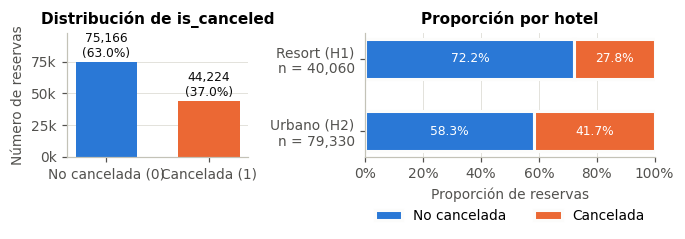

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.5), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
conteo = df[Y].value_counts().sort_index()
barras = ax.bar(["No cancelada (0)", "Cancelada (1)"], conteo.values, color=[AZUL, NARANJA], width=0.6)
for b, v in zip(barras, conteo.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 1500, f"{v:,}\n({v / len(df):.1%})",
            ha="center", va="bottom", fontsize=8, color=TINTA)
ax.set_ylim(0, conteo.max() * 1.3)
ax.set_ylabel("Número de reservas")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1000:.0f}k"))
ax.set_title("Distribución de is_canceled")
ax.grid(axis="x", visible=False)

ax = axes[1]
tab = pd.crosstab(df["hotel"], df[Y], normalize="index").rename(
    index={"City Hotel": "Urbano (H2)", "Resort Hotel": "Resort (H1)"})
izq = np.zeros(len(tab))
for clase, color, lab in [(0, AZUL, "No cancelada"), (1, NARANJA, "Cancelada")]:
    ax.barh(tab.index, tab[clase], left=izq, color=color, height=0.55, label=lab,
            edgecolor="#fcfcfb", linewidth=2)
    for i, v in enumerate(tab[clase]):
        ax.text(izq[i] + v / 2, i, f"{v:.1%}", ha="center", va="center", color="white", fontsize=8)
    izq += tab[clase].values
n_h = df["hotel"].value_counts().rename(index={"City Hotel": "Urbano (H2)", "Resort Hotel": "Resort (H1)"})
ax.set_yticks(range(len(tab)), [f"{h}\nn = {n_h[h]:,}" for h in tab.index])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlim(0, 1)
ax.set_xlabel("Proporción de reservas")
ax.set_title("Proporción por hotel")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2)
ax.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, "fig1_objetivo")

**Insight:** desbalance moderado (63/37), que **no** justifica sobremuestreo agresivo pero sí
estratificación y métricas sensibles a la clase positiva (PR-AUC, F1, *recall*). El exactitud
(*accuracy*) de un clasificador trivial que predice "no cancela" ya sería 63 %, así que no sirve
como métrica principal. La tasa difiere mucho entre hoteles (41.7 % vs 27.8 %): `hotel` debe
entrar como variable y conviene reportar métricas por hotel.

## 5. Auditoría de fuga de información (*target leakage*)

Pregunta para cada variable: **¿estaría disponible en el momento en que el hotel necesita la
predicción?** El artículo fuente fija el punto de observación en "el día previo a la llegada",
pero documenta que algunas variables se registran hasta el *check-in* o la cancelación.

In [13]:
fuga = pd.DataFrame([
    ("reservation_status ∈ {Canceled, No-Show}", df["reservation_status"].ne("Check-Out")),
    ("reservation_status = Check-Out", df["reservation_status"].eq("Check-Out")),
    ("Habitación asignada ≠ reservada", df["reserved_room_type"] != df["assigned_room_type"]),
    ("Habitación asignada = reservada", df["reserved_room_type"] == df["assigned_room_type"]),
    ("Solicita estacionamiento (≥1)", df["required_car_parking_spaces"] > 0),
    ("No solicita estacionamiento", df["required_car_parking_spaces"] == 0),
    ("País = PRT", df["country"].eq("PRT")),
    ("País ≠ PRT", df["country"].ne("PRT") & df["country"].notna()),
    ("Depósito = Non Refund", df["deposit_type"].eq("Non Refund")),
    ("Depósito ≠ Non Refund", df["deposit_type"].ne("Non Refund")),
], columns=["condicion", "mask"])
fuga["n"] = fuga["mask"].apply(np.sum)
fuga["tasa"] = fuga["mask"].apply(lambda m: df.loc[m, Y].mean())
print(pd.crosstab(df["reservation_status"], df[Y]))
fuga[["condicion", "n", "tasa"]]

is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207


,condicion,n,tasa
0,"reservation_status ∈ {Canceled, No-Show}",44224,1.000000
1,reservation_status = Check-Out,75166,0.000000
2,Habitación asignada ≠ reservada,14917,0.053764
3,Habitación asignada = reservada,104473,0.415629
4,Solicita estacionamiento (≥1),7416,0.000000
5,No solicita estacionamiento,111974,0.394949
6,País = PRT,48590,0.566351
7,País ≠ PRT,70312,0.236631
8,Depósito = Non Refund,14587,0.993624
9,Depósito ≠ Non Refund,104803,0.283675


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


... (326 outputs left out)

findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


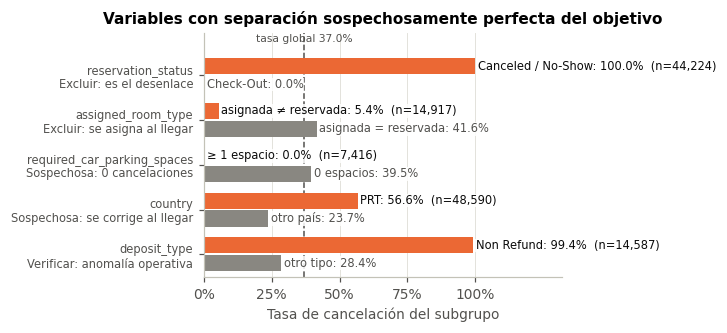

In [14]:
pares = [
    ("reservation_status", "Canceled / No-Show", "Check-Out", 0, 1, "Excluir: es el desenlace"),
    ("assigned_room_type", "asignada ≠ reservada", "asignada = reservada", 2, 3, "Excluir: se asigna al llegar"),
    ("required_car_parking_spaces", "≥ 1 espacio", "0 espacios", 4, 5, "Sospechosa: 0 cancelaciones"),
    ("country", "PRT", "otro país", 6, 7, "Sospechosa: se corrige al llegar"),
    ("deposit_type", "Non Refund", "otro tipo", 8, 9, "Verificar: anomalía operativa"),
]
fig, ax = plt.subplots(figsize=(6.3, 3.1))
alto = 0.36
for i, (var, la, lb, ia, ib, veredicto) in enumerate(pares):
    ya, yb = i - alto / 2 - 0.02, i + alto / 2 + 0.02
    ta, tb = fuga.loc[ia, "tasa"], fuga.loc[ib, "tasa"]
    ax.barh(ya, ta, height=alto, color=NARANJA)
    ax.barh(yb, tb, height=alto, color=GRIS)
    ax.text(max(ta, 0) + 0.01, ya, f"{la}: {ta:.1%}  (n={fuga.loc[ia, 'n']:,})", va="center", fontsize=7.5, color=TINTA,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.5, alpha=0.85))
    ax.text(tb + 0.01, yb, f"{lb}: {tb:.1%}", va="center", fontsize=7.5, color=TINTA2,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.5, alpha=0.85))
ax.set_yticks(range(len(pares)), [f"{p[0]}\n{p[5]}" for p in pares], fontsize=7.5)
ax.axvline(df[Y].mean(), color=TINTA2, lw=1, ls="--", zorder=0)
ax.text(df[Y].mean(), -0.75, f"tasa global {df[Y].mean():.1%}", fontsize=7, color=TINTA2, ha="center")
ax.set_ylim(len(pares) - 0.5, -0.95)
ax.set_xlim(0, 1.32)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xticks(np.arange(0, 1.01, .25))
ax.set_xlabel("Tasa de cancelación del subgrupo")
ax.set_title("Variables con separación sospechosamente perfecta del objetivo")
ax.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, "fig2_fuga")

**Insight (decisión crítica para la Entrega 2):**

- `reservation_status` reproduce el objetivo al 100 % y `reservation_status_date` es la fecha
  de ese desenlace → **se excluyen**.
- Cuando la habitación asignada difiere de la reservada, la cancelación cae a 5.4 %: la
  asignación ocurre al llegar el huésped, así que es una consecuencia de *no* cancelar →
  **se excluye `assigned_room_type`** (se conserva `reserved_room_type`).
- Ninguna de las 7,416 reservas con estacionamiento se canceló (0.0 %). Una separación perfecta
  en una variable "inocente" es una bandera roja: probablemente se registra en el *check-in*.
  → **sospechosa**; se evaluará el modelo con y sin ella.
- PRT cancela 56.6 % vs 23.6 %. El artículo fuente indica que la nacionalidad a menudo se
  conoce hasta el *check-in*; un modelo podría aprender "PRT = país por defecto todavía no
  corregido" → **sospechosa**.
- `booking_changes` se cuenta "hasta el *check-in* o la cancelación" (artículo fuente) →
  riesgo de fuga parcial; se tratará igual que las sospechosas.
- *Non Refund* cancela 99.4 %: contraintuitivo (pagar sin reembolso debería disuadir). Se
  documenta como anomalía operativa (bloques de grupos/agencias) más que como fuga.

## 6. Distribuciones clave: anticipación de la reserva (`lead_time`)

findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


... (513 outputs left out)

findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


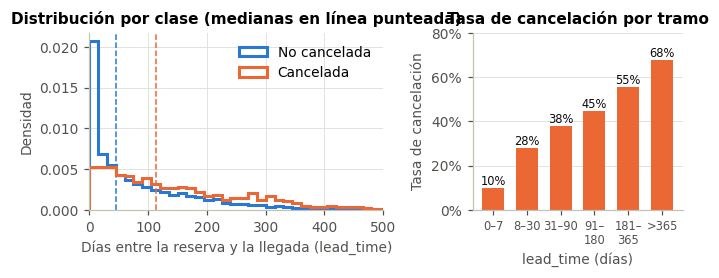

In [15]:
print(df.groupby(Y)["lead_time"].describe().round(1))
fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.6), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
bins = np.arange(0, 740, 15)
for clase, color, lab in [(0, AZUL, "No cancelada"), (1, NARANJA, "Cancelada")]:
    ax.hist(df.loc[df[Y] == clase, "lead_time"], bins=bins, density=True, histtype="step",
            lw=2, color=color, label=lab)
    med = df.loc[df[Y] == clase, "lead_time"].median()
    ax.axvline(med, color=color, ls="--", lw=1)
    print(f"Mediana lead_time clase {clase}: {med:.0f} días")
ax.set_xlim(0, 500)
ax.set_xlabel("Días entre la reserva y la llegada (lead_time)")
ax.set_ylabel("Densidad")
ax.set_title("Distribución por clase (medianas en línea punteada)")
ax.legend()
ax = axes[1]
cortes = [-1, 7, 30, 90, 180, 365, 800]
etq = ["0–7", "8–30", "31–90", "91–\n180", "181–\n365", ">365"]
tb = df.groupby(pd.cut(df["lead_time"], cortes, labels=etq), observed=True)[Y].agg(["mean", "size"])
ax.bar(tb.index.astype(str), tb["mean"], color=NARANJA, width=0.65)
for i, (m, n) in enumerate(zip(tb["mean"], tb["size"])):
    ax.text(i, m + 0.015, f"{m:.0%}", ha="center", fontsize=7.5, color=TINTA)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylim(0, 0.8)
ax.set_xlabel("lead_time (días)")
ax.set_ylabel("Tasa de cancelación")
ax.set_title("Tasa de cancelación por tramo")
ax.tick_params(axis="x", labelsize=7.5)
ax.grid(axis="x", visible=False)
fig.tight_layout()
guardar(fig, "fig3_leadtime")
tb

**Insight:** la mediana de anticipación de las canceladas (113 días) es 2.5 veces la de las no
canceladas (45 días) y la tasa de cancelación crece de forma monótona con la anticipación.
Es la variable legítima más asociada al objetivo (Spearman 0.32). La relación es monótona pero
no lineal y la distribución tiene cola larga a la derecha: para la regresión logística convendrá
una transformación logarítmica o por tramos; los modelos de árboles no la requieren.

## 7. Segmentos comerciales: depósito y segmento de mercado

findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


... (314 outputs left out)

findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


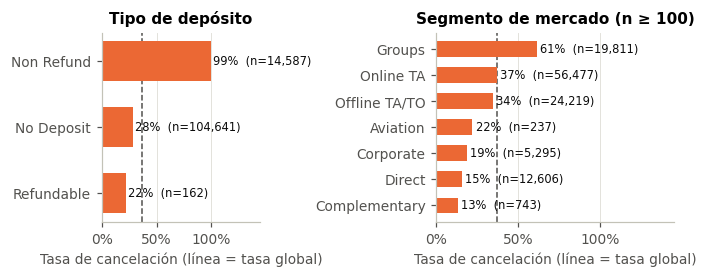

In [16]:
seg = (df.groupby("market_segment")[Y].agg(["mean", "size"])
         .query("size >= 100").sort_values("mean"))
dep = df.groupby("deposit_type")[Y].agg(["mean", "size"]).sort_values("mean")
print(pd.crosstab(df["deposit_type"], df["market_segment"], normalize="index").round(3))
fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.6), gridspec_kw={"width_ratios": [1, 1.5]})
for ax, t, tit in [(axes[0], dep, "Tipo de depósito"), (axes[1], seg, "Segmento de mercado (n ≥ 100)")]:
    ax.barh(t.index, t["mean"], color=NARANJA, height=0.6)
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(m + 0.02, i, f"{m:.0%}  (n={n:,})", va="center", fontsize=7.5, color=TINTA)
    ax.set_xlim(0, 1.45)
    ax.set_xticks([0, .5, 1])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax.axvline(df[Y].mean(), color=TINTA2, lw=1, ls="--", zorder=0)
    ax.set_xlabel("Tasa de cancelación (línea = tasa global)")
    ax.set_title(tit)
    ax.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, "fig4_segmentos")

**Insight:** las reservas *Non Refund* cancelan 99.4 %, al revés de lo esperado. El cruce con
`market_segment` muestra que se concentran en *Groups* y *Offline TA/TO*: son bloques que las
agencias reservan y liberan en masa. Para el negocio, esto significa que el riesgo está en el
canal, no en el cliente individual. Para el modelo, `deposit_type` tendrá una importancia enorme
y debe interpretarse con cuidado (correlación operativa, no causal).

## 8. Estructura temporal

findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


... (282 outputs left out)

findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


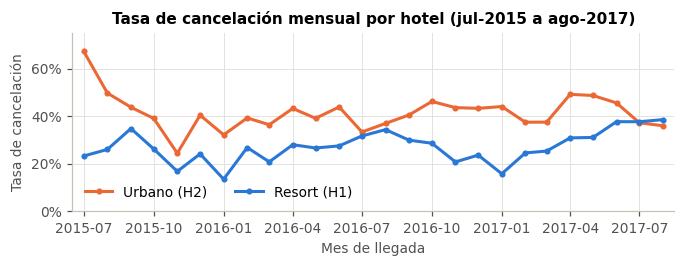

In [17]:
mes = (df.assign(mes=df["fecha_llegada"].dt.to_period("M").dt.to_timestamp())
         .groupby(["mes", "hotel"])[Y].mean().unstack())
fig, ax = plt.subplots(figsize=(6.3, 2.5))
for h, color, lab in [("City Hotel", NARANJA, "Urbano (H2)"), ("Resort Hotel", AZUL, "Resort (H1)")]:
    ax.plot(mes.index, mes[h], color=color, lw=2, marker="o", ms=3, label=lab)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylim(0, 0.75)
ax.set_ylabel("Tasa de cancelación")
ax.set_xlabel("Mes de llegada")
ax.set_title("Tasa de cancelación mensual por hotel (jul-2015 a ago-2017)")
ax.legend(loc="lower left", ncol=2)
ax.set_xlim(mes.index[0] - pd.Timedelta(days=15), mes.index[-1] + pd.Timedelta(days=15))
fig.tight_layout()
guardar(fig, "fig5_temporal")
print(mes.agg(["min", "idxmin", "max", "idxmax"]))
mes.describe().round(3)

**Insight:** la tasa mensual oscila entre 24.4 % y 67.2 % en el hotel urbano y entre 13.5 % y
38.5 % en el resort, con estacionalidad distinta en cada hotel y sin un ciclo idéntico de un año
a otro. En el resort, además, la tasa sube de forma sostenida durante 2017 (deriva temporal). Esto tiene dos consecuencias metodológicas:
(1) `arrival_date_year` no debe usarse como predictor (en producción solo habrá años futuros);
(2) una partición aleatoria mezclaría meses futuros en el entrenamiento. Se propone reservar los
**últimos meses de llegadas como conjunto de prueba** (validación temporal) para estimar el
desempeño de forma realista.

## 9. Correlaciones
### 9.1 Entre variables numéricas (Spearman)
Se usa Spearman porque casi todas las variables numéricas son conteos asimétricos con
colas largas; Pearson se dejaría dominar por los *outliers* (p. ej., ADR = 5,400).

findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


... (583 outputs left out)

findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


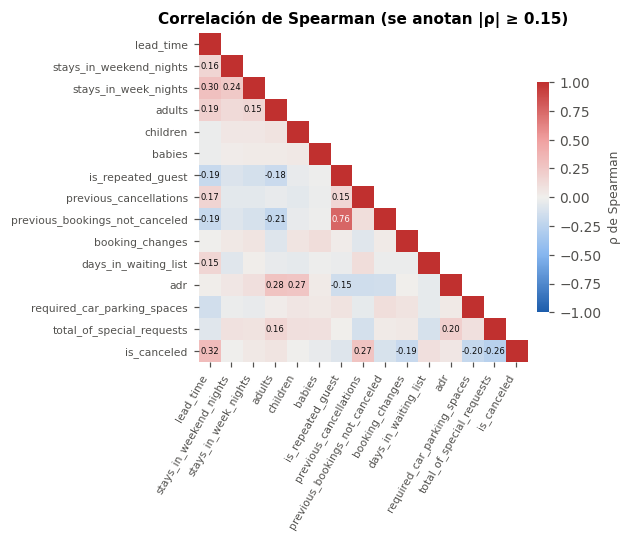

In [18]:
num = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
       "babies", "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
       "booking_changes", "days_in_waiting_list", "adr", "required_car_parking_spaces",
       "total_of_special_requests", Y]
corr = df[num].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.3, 5.0))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a0a0", "#c0302f"])
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
im = ax.imshow(np.ma.array(corr, mask=mask), cmap=cmap, vmin=-1, vmax=1)
for i in range(len(num)):
    for j in range(i + 1):
        v = corr.iloc[i, j]
        if i != j and abs(v) >= 0.15:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=5.5,
                    color="white" if abs(v) > 0.6 else TINTA)
ax.set_xticks(range(len(num)), num, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(len(num)), num, fontsize=7)
ax.grid(False)
ax.spines[:].set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.7, pad=0.02)
cb.set_label("ρ de Spearman", fontsize=8)
cb.outline.set_visible(False)
ax.set_title("Correlación de Spearman (se anotan |ρ| ≥ 0.15)")
fig.tight_layout()
guardar(fig, "fig6_spearman")
corr[Y].drop(Y).sort_values(key=abs, ascending=False).round(3)

**Insight:** el único par de predictoras fuertemente correlacionado es `is_repeated_guest` y
`previous_bookings_not_canceled` (ρ = 0.76), lo cual es lógico: ambas describen el historial del
cliente. Afecta la interpretación de coeficientes en la regresión logística (se repartirán el
efecto), pero no a los árboles; el resto de pares tiene |ρ| ≤ 0.30. Las asociaciones con el objetivo son
moderadas: `lead_time` (+0.32), `previous_cancellations` (+0.27), `total_of_special_requests`
(−0.26). La señal está repartida y es no lineal, lo que favorece modelos de ensamble de árboles
frente a un modelo lineal.

### 9.2 Asociación de todas las variables con el objetivo
Para comparar variables numéricas y categóricas en la misma escala [0, 1] se usa |ρ| de Spearman
(numéricas) y la V de Cramér con corrección de sesgo (categóricas). La corrección es necesaria
porque la V sin corregir se infla con variables de muchas categorías (`country`: 177, `agent`: 333).

findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


... (759 outputs left out)

findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


findfont: Font family 'Inter' not found.


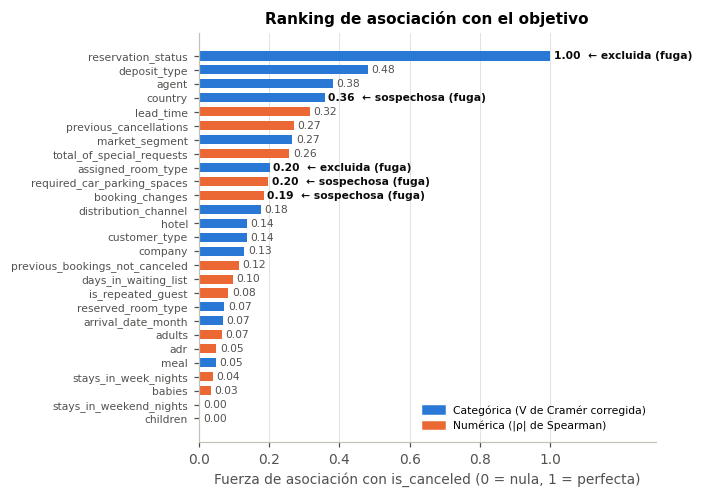

In [19]:
def cramers_v_corregida(x, y):
    """V de Cramér con corrección de sesgo de Bergsma (2013)."""
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.to_numpy().sum()
    r, k = tabla.shape
    phi2 = chi2 / n
    phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2c / max(1e-12, min(kc - 1, rc - 1)))


cat = ["hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel",
       "reserved_room_type", "assigned_room_type", "deposit_type", "agent", "company",
       "customer_type", "reservation_status"]
asoc = []
for c in cat:
    asoc.append((c, "Categórica (V de Cramér)", cramers_v_corregida(df[c].fillna("Sin dato"), df[Y])))
for c in num[:-1]:
    asoc.append((c, "Numérica (|ρ| de Spearman)", abs(spearmanr(df[c], df[Y], nan_policy="omit")[0])))
asoc = pd.DataFrame(asoc, columns=["variable", "tipo", "asociacion"]).sort_values("asociacion")
sospechosas = {"reservation_status": "excluida", "assigned_room_type": "excluida",
               "required_car_parking_spaces": "sospechosa", "country": "sospechosa",
               "booking_changes": "sospechosa"}

fig, ax = plt.subplots(figsize=(6.3, 4.6))
colores = asoc["tipo"].map({"Categórica (V de Cramér)": AZUL, "Numérica (|ρ| de Spearman)": NARANJA})
ax.barh(asoc["variable"], asoc["asociacion"], color=colores, height=0.65)
for i, (v, a) in enumerate(zip(asoc["variable"], asoc["asociacion"])):
    marca = f"  ← {sospechosas[v]} (fuga)" if v in sospechosas else ""
    ax.text(a + 0.01, i, f"{a:.2f}{marca}", va="center", fontsize=7, color=TINTA if marca else TINTA2,
            fontweight="bold" if marca else "normal")
ax.set_xlim(0, 1.3)
ax.set_xticks(np.arange(0, 1.01, .2))
ax.tick_params(axis="y", labelsize=7)
ax.set_xlabel("Fuerza de asociación con is_canceled (0 = nula, 1 = perfecta)")
ax.set_title("Ranking de asociación con el objetivo")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label="Categórica (V de Cramér corregida)"),
                   Patch(color=NARANJA, label="Numérica (|ρ| de Spearman)")], loc="lower right", fontsize=7)
ax.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, "fig7_asociacion")
asoc.sort_values("asociacion", ascending=False).round(3)

**Insight:** el *ranking* lo encabeza `reservation_status` (V = 1.0, fuga total), y 5 de las 11
variables más asociadas son excluidas o sospechosas de fuga (`country` es la 4.ª).
Es decir, **varias de las variables "más predictivas" son justamente las sospechosas de fuga**.
Además, la correlación *subestima* la fuga de `required_car_parking_spaces` (ρ = 0.20 pese a que
ninguna reserva con estacionamiento se canceló): por eso la auditoría se hizo por subgrupos (§5) y
no solo con coeficientes de correlación.
Un modelo entrenado sin esta auditoría reportaría métricas casi perfectas que no se reproducirían
en operación. Entre las legítimas destacan `deposit_type`, `agent`, `market_segment` y `lead_time`.
`agent` y `company` tienen asociación alta pero cientos de categorías raras: en la Entrega 2 se
agruparán las categorías poco frecuentes y se codificarán dentro de la validación cruzada.

## 10. Diccionario de datos (se exporta a LaTeX)

In [20]:
dic = [
    # variable, tipo, unidad/dominio, descripción, rol
    ("hotel", "Categórica", "{Resort Hotel, City Hotel}", "Hotel de la reserva (H1 resort, H2 urbano)", "Predictora"),
    ("is\\_canceled", "Binaria", "{0, 1}", "1 si la reserva fue cancelada", "\\textbf{Objetivo}"),
    ("lead\\_time", "Entera", "días, [0, 737]", "Días entre el registro de la reserva y la llegada", "Predictora"),
    ("arrival\\_date\\_year", "Entera", "{2015, 2016, 2017}", "Año de llegada", "Excluida (no recurrente)"),
    ("arrival\\_date\\_month", "Categórica", "enero–diciembre", "Mes de llegada", "Predictora"),
    ("arrival\\_date\\_week\\_number", "Entera", "semana, [1, 53]", "Semana del año de llegada", "Predictora"),
    ("arrival\\_date\\_day\\_of\\_month", "Entera", "día, [1, 31]", "Día del mes de llegada", "Predictora"),
    ("stays\\_in\\_weekend\\_nights", "Entera", "noches, [0, 19]", "Noches de sábado o domingo reservadas", "Predictora"),
    ("stays\\_in\\_week\\_nights", "Entera", "noches, [0, 50]", "Noches de lunes a viernes reservadas", "Predictora"),
    ("adults", "Entera", "personas, [0, 55]", "Número de adultos", "Predictora"),
    ("children", "Entera", "personas, [0, 10]", "Número de niños", "Predictora"),
    ("babies", "Entera", "personas, [0, 10]", "Número de bebés", "Predictora"),
    ("meal", "Categórica", "{BB, HB, FB, SC, Undefined}", "Plan de alimentos; SC y Undefined = sin plan", "Predictora"),
    ("country", "Categórica", "ISO 3166-1 alfa-3 (177)", "País de origen del huésped", "Sospechosa de fuga"),
    ("market\\_segment", "Categórica", "8 niveles", "Segmento de mercado (TA = agencias, TO = operadores)", "Predictora"),
    ("distribution\\_channel", "Categórica", "5 niveles", "Canal de distribución de la reserva", "Predictora"),
    ("is\\_repeated\\_guest", "Binaria", "{0, 1}", "1 si el huésped tiene reservas previas", "Predictora"),
    ("previous\\_cancellations", "Entera", "reservas, [0, 26]", "Cancelaciones previas del mismo cliente", "Predictora"),
    ("previous\\_bookings\\_not\\_canceled", "Entera", "reservas, [0, 72]", "Reservas previas no canceladas del cliente", "Predictora"),
    ("reserved\\_room\\_type", "Categórica", "10 códigos", "Tipo de habitación reservada (código anonimizado)", "Predictora"),
    ("assigned\\_room\\_type", "Categórica", "12 códigos", "Tipo de habitación asignada", "Excluida (fuga)"),
    ("booking\\_changes", "Entera", "cambios, [0, 21]", "Modificaciones hasta el \\emph{check-in} o la cancelación", "Sospechosa de fuga"),
    ("deposit\\_type", "Categórica", "{No Deposit, Non Refund, Refundable}", "Tipo de depósito garantizado", "Predictora"),
    ("agent", "Categórica", "ID (333)", "Agencia que hizo la reserva; nulo = sin agencia", "Predictora"),
    ("company", "Categórica", "ID (352)", "Empresa responsable; nulo = no aplica", "Predictora"),
    ("days\\_in\\_waiting\\_list", "Entera", "días, [0, 391]", "Días en lista de espera antes de confirmar", "Predictora"),
    ("customer\\_type", "Categórica", "4 niveles", "Contract, Group, Transient, Transient-Party", "Predictora"),
    ("adr", "Continua", "moneda/noche, [-6.38, 5400]", "Tarifa diaria promedio (\\emph{Average Daily Rate})", "Predictora"),
    ("required\\_car\\_parking\\_spaces", "Entera", "espacios, [0, 8]", "Espacios de estacionamiento solicitados", "Sospechosa de fuga"),
    ("total\\_of\\_special\\_requests", "Entera", "solicitudes, [0, 5]", "Solicitudes especiales (cama, piso, etc.)", "Predictora"),
    ("reservation\\_status", "Categórica", "{Canceled, Check-Out, No-Show}", "Último estado de la reserva", "Excluida (fuga)"),
    ("reservation\\_status\\_date", "Fecha", "2014-10-17 a 2017-09-14", "Fecha del último estado", "Excluida (fuga)"),
]
nul = df.isna().mean()
with open(TAB / "diccionario.tex", "w") as f:
    for v, t, u, d, r in dic:
        p = nul[v.replace("\\_", "_")]
        ptxt = "0" if p == 0 else (f"{100 * p:.2f}" if p < 0.01 else f"{100 * p:.1f}")
        u = u.replace("{", "\\{").replace("}", "\\}").replace("\\{0, 1\\}", "\\{0, 1\\}")
        f.write(f"\\texttt{{{v}}} & {t} & {u} & {d} & {r} & {ptxt} \\\\\n")
print(f"{len(dic)} variables exportadas")

32 variables exportadas


## 11. Bitácora de decisiones derivadas del EDA (insumo para la Entrega 2)

| # | Hallazgo | Decisión propuesta | Alternativa descartada |
|---|---|---|---|
| 1 | `reservation_status(_date)` y `assigned_room_type` revelan el desenlace | Excluir | Conservar (métricas infladas) |
| 2 | `required_car_parking_spaces`, `country`, `booking_changes` con posible registro posterior | Modelo con y sin ellas; reportar ambos | Incluirlas sin advertencia |
| 3 | 26.8 % de filas duplicadas, con mayor tasa de cancelación | Validación agrupada o temporal | Eliminar duplicados a ciegas |
| 4 | Tasa de cancelación varía por mes y año | Prueba = últimos meses de llegadas; excluir `arrival_date_year` | Partición aleatoria |
| 5 | `agent`/`company` nulos = "no aplica" | Categoría propia + bandera | Imputar con la moda |
| 6 | `country` nulo informativo (13.7 % vs 37.1 %) | Categoría "Desconocido" | Imputar PRT |
| 7 | `children` 4 nulos | Imputar 0 (mediana) dentro del Pipeline | Eliminar filas (irrelevante pero inconsistente) |
| 8 | ADR = 5,400 y ADR < 0 | Tratar como error: recorte por percentil ajustado en entrenamiento | Eliminar todo ADR = 0 (es legítimo) |
| 9 | 180 reservas con cero huéspedes | Eliminar (imposibles) | Conservar |
| 10 | Desbalance 63/37 | Estratificación + `class_weight` + PR-AUC/F1 | SMOTE fuera de la validación cruzada |
| 11 | `lead_time` asimétrico y no lineal | log1p para modelo lineal; crudo para árboles | Recorte IQR (elimina señal) |